# **Sesión 2:** Calibración de Cámara 📷⚙️

## 0. Preparación

In [1]:
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)
from typing import List
import numpy as np
# import imageio --- IGNORE IF DEPRECATED---
import imageio.v3 as imageio
import copy
import os
import glob

OpenCV should be 4.8.x Current version: 4.14.0


## **Apartado A: Calibración de cámara** (derecha e izquierda)

En este apartado se realiza la calibración de dos cámaras de un sistema estereoscópico. Para ello se trabajará con las imágenes de las carpetas ``left`` y ``right``. En primer lugar se trabajará con la carpeta ``left``. Posteriormente, deberá repetir el proceso con las imágenes en la carpeta ``right``. Ambas carpetas contienen imágenes con las que se calibrarán las cámaras. En ellas aparece el patrón de calibración en diferentes posiciones y orientaciones. Estas imágenes serán los datos de entrada.

Los pasos que deberá seguir para calibrar una cámara son:

1. Defina y ejecute el método para cargar imágenes ``load_images()``.
2. Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.
3. Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``.
4. Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)`` que proporcione las coordenadas 3D de las esquinas del patrón. El sistema de referencia utilizado deberá estar anclado al propio patrón.
5. Utilice ``cv2.calibrateCamera`` para obtener los parámetros de calibración para la cámara izquierda.

### **Tarea A.1:** Defina y ejecute el método para cargar imágenes ``load_images()``.

In [2]:
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

In [3]:
# Paths of all images taken with our webcam (folder "calib")
imgs_path = sorted(glob.glob("../data/calibracion/*.jpg"))
imgs = load_images(imgs_path)

imgs_path

['../data/calibracion\\WIN_20261113_18_30_25_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_30_26_Pro (2).jpg',
 '../data/calibracion\\WIN_20261113_18_30_26_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_30_27_Pro (3).jpg',
 '../data/calibracion\\WIN_20261113_18_30_28_Pro (2).jpg',
 '../data/calibracion\\WIN_20261113_18_30_28_Pro (4).jpg',
 '../data/calibracion\\WIN_20261113_18_30_28_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_30_29_Pro (2).jpg',
 '../data/calibracion\\WIN_20261113_18_30_29_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_30_30_Pro (3).jpg',
 '../data/calibracion\\WIN_20261113_18_50_27_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_28_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_32_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_33_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_36_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_37_Pro.jpg',
 '../data/calibracion\\WIN_20261113_18_50_40_Pro.jpg']

### **Tarea A.2:** Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.

In [4]:
# Study which winSize use
imgs[0].shape

(1080, 1920, 3)

In [5]:
# TODO Find corners with cv2.findChessboardCorners()
# Hint: you can use a list comprehension to process all images
# (8,6) = esquinas INTERIORES del tablero impreso. Cambiar si el vuestro es distinto
corners = [cv2.findChessboardCorners(img, (10 , 7), None) for img in imgs]


In [6]:
corners_copy = copy.deepcopy(corners)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs]
for i in range(len(imgs_gray)):
    ret, img_corners = corners_copy[i]
    
    # We refine only the images whose pattern has been find by openCV
    if ret == True:
        # cv2.cornerSubPix(imagen, esquinas, winSize, zeroZone, criteria)
        cv2.cornerSubPix(imgs_gray[i], img_corners, (5,5), (-1, -1), criteria)
    else:
        print(i)


### **Tarea A.3:** Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``

In [7]:
imgs_copy = copy.deepcopy(imgs)

In [8]:
# TODO Use cv2.drawChessboardCorners() to draw the cornes

for i in range(len(imgs_copy)):
    # We unpack the boolean and the coordinates (already refined)
    ret, img_corners = corners_copy[i]
    
    # Draw
    cv2.drawChessboardCorners(
        image=imgs_copy[i],
        patternSize= (10, 7),
        corners = img_corners,
        patternWasFound = ret )

In [9]:
# TODO Show images and save when needed

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)
    cv2.imwrite(img_path, img)

In [10]:
# Resize to watch better the images
for i in range(len(imgs_copy)):
    img = imgs_copy[i]
    img = cv2.resize(img, (850, 650))
    show_image(img)

### **Tarea A.4:** Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)``

In [11]:
# TODO Design the method. It should return a np.array with np.float32 elements
import numpy as np

def get_chessboard_points(chessboard_shape, dx, dy):
    cols, rows = chessboard_shape

    pts = np.zeros((rows * cols, 3), dtype=np.float32)
    pts[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2) * (dx, dy)
    return pts
    

In [12]:
# TODO You need the points for every image, not just one (consider a list comprehension)
chessboard_shape = (10,7)
dx = dy = 15.0 # mms -> MEDIR con regla el lado de una casilla del tablero impreso
chessboard_points = get_chessboard_points(chessboard_shape, dx, dy)

# I can print every imagen (ret=true) because every one achieve it
chessboard_points

array([[  0.,   0.,   0.],
       [ 15.,   0.,   0.],
       [ 30.,   0.,   0.],
       [ 45.,   0.,   0.],
       [ 60.,   0.,   0.],
       [ 75.,   0.,   0.],
       [ 90.,   0.,   0.],
       [105.,   0.,   0.],
       [120.,   0.,   0.],
       [135.,   0.,   0.],
       [  0.,  15.,   0.],
       [ 15.,  15.,   0.],
       [ 30.,  15.,   0.],
       [ 45.,  15.,   0.],
       [ 60.,  15.,   0.],
       [ 75.,  15.,   0.],
       [ 90.,  15.,   0.],
       [105.,  15.,   0.],
       [120.,  15.,   0.],
       [135.,  15.,   0.],
       [  0.,  30.,   0.],
       [ 15.,  30.,   0.],
       [ 30.,  30.,   0.],
       [ 45.,  30.,   0.],
       [ 60.,  30.,   0.],
       [ 75.,  30.,   0.],
       [ 90.,  30.,   0.],
       [105.,  30.,   0.],
       [120.,  30.,   0.],
       [135.,  30.,   0.],
       [  0.,  45.,   0.],
       [ 15.,  45.,   0.],
       [ 30.,  45.,   0.],
       [ 45.,  45.,   0.],
       [ 60.,  45.,   0.],
       [ 75.,  45.,   0.],
       [ 90.,  45.,   0.],
 

In [13]:
chessboard_points.shape

(70, 3)

### **Tarea A.5:** Utilice ``cv2.calibrateCamera()`` para obtener los parámetros de calibración para la cámara izquierda

In [14]:
# Filter data and get only those with adequate detections
# Convert list to numpy array with np.float32 elements
valid_corners = [corners.astype(np.float32) for ret, corners in corners_copy if ret]
len(valid_corners)

17

In [15]:
# TODO
img_size = imgs_gray[0].shape[::-1] # (width, height) = (320, 240)

object_points = [chessboard_points for _ in valid_corners]

rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
    object_points,
    valid_corners,
    img_size,
    None,
    None,
    flags=cv2.CALIB_FIX_K3
)

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))

In [16]:
print("Extrinsics:",extrinsics)

Extrinsics: [array([[ 9.98413929e-01,  5.62909482e-02,  9.77005047e-04,
        -1.10720383e+02],
       [-5.62069700e-02,  9.97618345e-01, -3.99801610e-02,
        -1.44033348e+01],
       [-3.22519933e-03,  3.98618352e-02,  9.99199996e-01,
         3.13787515e+02]]), array([[ 9.99249383e-01,  3.84276035e-02,  4.89787177e-03,
        -1.09189332e+02],
       [-3.82592584e-02,  9.98793932e-01, -3.07719045e-02,
        -1.96861936e+01],
       [-6.07445515e-03,  3.05614177e-02,  9.99514432e-01,
         3.16235883e+02]]), array([[ 9.98571394e-01,  5.31317953e-02,  5.67307679e-03,
        -1.10099543e+02],
       [-5.28684206e-02,  9.97825114e-01, -3.93696840e-02,
        -1.65793399e+01],
       [-7.75252048e-03,  3.90135136e-02,  9.99208609e-01,
         3.16090772e+02]]), array([[ 9.81117603e-01, -1.93191104e-01,  9.24371302e-03,
        -1.34672529e+02],
       [ 1.93360482e-01,  9.80839128e-01, -2.37976600e-02,
        -6.57802564e+01],
       [-4.46909921e-03,  2.51356719e-02,  9.9

In [17]:
# Print outputs
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[1.34643481e+03 0.00000000e+00 9.53322089e+02]
 [0.00000000e+00 1.35006329e+03 5.12835763e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion coefficients:
 [[ 0.17419328 -0.39638767 -0.0017908  -0.00520057  0.        ]]
Root mean squared reprojection error:
 0.44430950080960147


In [18]:
# Save calibration to reuse it in the project
np.savez("calibracion.npz", K=intrinsics, dist=dist_coeffs, rms=rms, img_size=img_size)

### **Pregunta A.2:** Diferencias entre cv2.findChessboardCorners() y cv2.cornerSubPix()

In [19]:
idx_img = 10
idx_corner = 10

corner_raw = corners[idx_img][1][idx_corner][0]           # find
corner_refined = corners_copy[idx_img][1][idx_corner][0]  # subPix

print("Antes:", corner_raw, " Después:", corner_refined, 
      " Desplazamiento:", corner_refined - corner_raw)

def crop_around(img, point, size=40):
    x, y = int(point[0]), int(point[1])
    return img[max(0,y-size):y+size, max(0,x-size):x+size]

img_before = imgs[idx_img].copy()
cv2.circle(img_before, tuple(corner_raw.astype(int)), 2, (0,0,255), -1)

img_after = imgs[idx_img].copy()
cv2.circle(img_after, tuple(corner_refined.astype(int)), 2, (0,255,0), -1)

crop_before = crop_around(img_before, corner_raw)
crop_after = crop_around(img_after, corner_refined)

crop_before = cv2.resize(crop_before, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)
crop_after = cv2.resize(crop_after, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)

cv2.putText(crop_before, "Antes (find)", (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,255), 1)
cv2.putText(crop_after, "Despues (subPix)", (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)

comparison = np.hstack([crop_before, crop_after])

show_image(comparison, "Antes vs Despues")

Antes: [711.10626 291.14017]  Después: [711.2145  290.65314]  Desplazamiento: [ 0.10821533 -0.48703003]


### **Pregunta A.3:** Número mínimo de imágenes necesarias para calibrar.

Imágenes válidas disponibles: 17


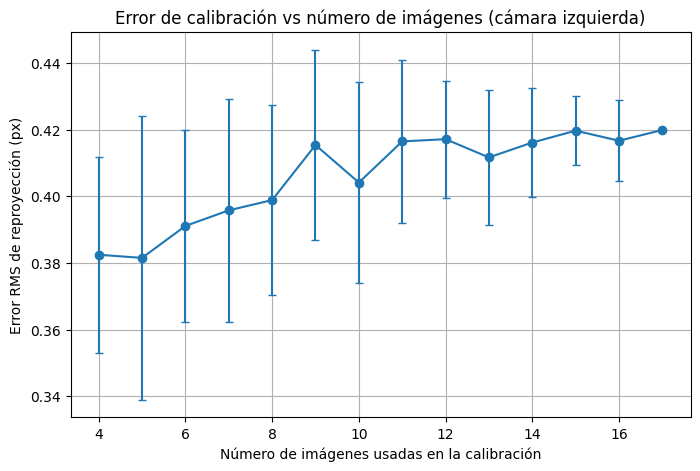

In [20]:
# TODO Homework
import random
import matplotlib.pyplot as plt

# left images
valid_corners = [corners.astype(np.float32) for ret, corners in corners_copy if ret]
n_total = len(valid_corners)
print("Imágenes válidas disponibles:", n_total)

n_repeats = 15 # repetitions for each subset size, to average
min_images = 4 # cv2.calibrateCamera needs at least a few views
sizes = list(range(min_images, n_total + 1))

mean_rms = []
std_rms = []

for n in sizes:
    errors = []
    for _ in range(n_repeats):
        idxs = random.sample(range(n_total), n)
        obj_pts = [chessboard_points for _ in idxs]
        img_pts = [valid_corners[i] for i in idxs]

        try:
            rms_n, _, _, _, _ = cv2.calibrateCamera(
                obj_pts, img_pts, img_size, None, None
            )
            errors.append(rms_n)
        except cv2.error:
            # Some combination might fail if the views are not very varied
            continue

    mean_rms.append(np.mean(errors))
    std_rms.append(np.std(errors))

plt.figure(figsize=(8,5))
plt.errorbar(sizes, mean_rms, yerr=std_rms, marker='o', capsize=3)
plt.xlabel("Número de imágenes usadas en la calibración")
plt.ylabel("Error RMS de reproyección (px)")
plt.title("Error de calibración vs número de imágenes (cámara izquierda)")
plt.grid(True)
plt.show()

## **Apartado B: Corrección de distorsión** (webcam)

Se cargan los parámetros guardados y se corrige la distorsión en vivo con ``cv2.initUndistortRectifyMap()`` y ``cv2.remap()``. A la izquierda la imagen original y a la derecha la corregida. Pulse q para salir.

In [21]:
calib = np.load("calibracion.npz")
K, dist = calib["K"], calib["dist"]
w, h = int(calib["img_size"][0]), int(calib["img_size"][1])

# Maps are computed once; then remap is applied to every frame
map1, map2 = cv2.initUndistortRectifyMap(K, dist, None, K, (w, h), cv2.CV_16SC2)

CAMERA_INDEX = 0
cap = cv2.VideoCapture(CAMERA_INDEX, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, w)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, h)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    undistorted = cv2.remap(frame, map1, map2, cv2.INTER_LINEAR)
    both = np.hstack([frame, undistorted])
    cv2.imshow("Original | Corregida", cv2.resize(both, None, fx=0.5, fy=0.5))
    key = cv2.waitKey(1) & 0xFF
    if key == ord('q') or key == 27:
        break

cap.release()
cv2.destroyAllWindows()